<div class="dark-title" style="background:linear-gradient(90deg,#1e3a8a,#5b21b6); color:#f1f5f9; padding:20px 32px; border-radius:8px; width:97%;"><style>.dark-title strong{color:#fde047;}</style>

## 🎁 全流程：子图当节点串起 4 个阶段，`recursion_limit` 的真相，评估贯穿全程

**一句话定位**：前四节的零件（节点函数、编译好的 supervisor 子图）直接 `add_node` 拼成一张图；最后加一个写报告节点。顺带纠正课程里 `recursion_limit` 的两处说法。
> 对应主课 `5_a_🔥_full_agent.ipynb`；langgraph 1.2.0 实测。

</div>

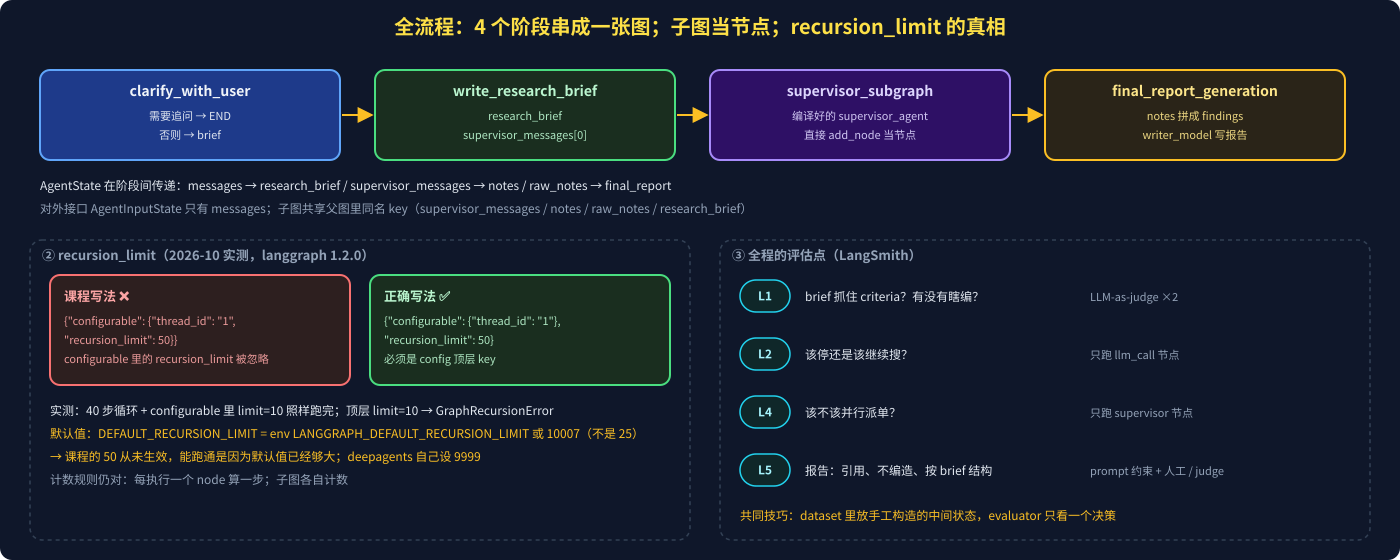

In [ ]:
from IPython.display import SVG
SVG(filename="assets/05_full_pipeline.svg")

### 1️⃣ 拼图：6 行 `add_node` / `add_edge`

In [ ]:
from langgraph.graph import StateGraph, START, END

b = StateGraph(AgentState, input_schema=AgentInputState)
b.add_node("clarify_with_user", clarify_with_user)            # 1_a 的节点函数（自己 Command 跳转）
b.add_node("write_research_brief", write_research_brief)
b.add_node("supervisor_subgraph", supervisor_agent)            # 🔑 编译好的子图直接当节点
b.add_node("final_report_generation", final_report_generation)
b.add_edge(START, "clarify_with_user")                         # clarify → brief 的边由 Command 决定，不用写
b.add_edge("write_research_brief", "supervisor_subgraph")
b.add_edge("supervisor_subgraph", "final_report_generation")
b.add_edge("final_report_generation", END)
agent = b.compile()                                            # langgraph.json 用这个；notebook 里再 compile(checkpointer=InMemorySaver())

| 机制 | 说明 |
|---|---|
| 子图当节点 | 父子 state **同名 key 自动共享**：`supervisor_messages` / `notes` / `raw_notes` / `research_brief` 在 `AgentState` 和 `SupervisorState` 里都有，所以 brief 流进去、notes 流出来 |
| `write_research_brief` 写 `supervisor_messages[0]` | 这就是子图的「第一条输入」 |
| `final_report_generation` | `notes` 拼成 `findings` → `final_report_generation_prompt(brief, findings, date)` → `writer_model.ainvoke`（`max_tokens=32000`）→ 同时写 `final_report` 和一条 `messages` 给用户 |
| 多轮 | 第一次 invoke 停在追问；同 `thread` 再 invoke 一次用户的回答 → 走完全程 |

### 2️⃣ `recursion_limit`：课程说法 vs 实测

| 课程说法 | 实测（langgraph 1.2.0，2026-10-21） |
|---|---|
| 默认 25 | `DEFAULT_RECURSION_LIMIT = int(getenv("LANGGRAPH_DEFAULT_RECURSION_LIMIT", "10007"))`；100 步循环不传 config 也跑完 |
| `{"configurable": {"thread_id": "1", "recursion_limit": 50}}` | **`configurable` 里的 `recursion_limit` 被忽略**：同样的图，这里写 10 照样跑 40 步；写在顶层 `{"recursion_limit": 10}` 才抛 `GraphRecursionError` |
| 每个 node 执行算一步、子图各自计数 | 正确 |

所以课程「调到 50」从未生效，能跑通是因为默认值本来就很大。真想设硬上限（防失控计费）：`config={"configurable": {"thread_id": ...}, "recursion_limit": 50}`。deepagents 在 `create_deep_agent` 里自己设 9999。

### 3️⃣ 报告 prompt 的约束 + 全程评估点

写报告 prompt 要求：按 brief 的问题类型决定结构（对比 / 列表 / 综述）、每条结论引用来源、不编造 brief 之外的内容、用 `findings` 原文细节。
全程四个评估点见上图：**每个评估都只测一个决策**，dataset 里放手工构造的中间状态（messages 轨迹），这是本课最可复用的测试方法论。

<div class="dark-warning" style="background:#2a2418; color:#fde68a; padding:12px 24px; border-left:4px solid #fbbf24; border-radius:4px; width:97%;"><style>.dark-warning strong{color:#f9a8d4;}</style>

**🆕 2026-10 对照**

| 本课阶段 | deepagents 官方 deep research（2026） |
|---|---|
| Scoping 两个节点 | prompt：先 `write_file("/research_request.md")`，不清楚直接问 |
| Research 子图 | 子代理 `research-agent` |
| Supervisor 子图 | 主代理 `write_todos` + `task`，3 并发 / 3 轮 |
| `final_report_generation` 节点 | 主代理 `write_file("/final_report.md")` 后回读请求核对覆盖度 |

部署名：LangGraph Platform → **LangSmith Deployment**；Studio 浏览器版；`langgraph dev` 不变。HITL 想接进来：`HumanInTheLoopMiddleware` / deepagents `interrupt_on=`（Agent Inbox 仓库 2026-09 已归档）。

</div>

<div class="dark-error" style="background:#2d1f1f; color:#fca5a5; padding:10px 24px; border-left:4px solid #f87171; border-radius:4px; width:97%;"><style>.dark-error strong{color:#fde047;}</style>

**坑**

| 坑 | 结果 |
|---|---|
| `recursion_limit` 写进 `configurable` | 无效（见上） |
| 子图与父图的 key 名不一致 | brief 进不去 / notes 出不来，报告为空 |
| `writer_model` 没设 `max_tokens` | 长报告截断 |
| 第二轮 invoke 换了 `thread_id` | 回到追问，永远到不了 supervisor |

</div>

<div class="dark-success" style="background:#1a2e1f; color:#bbf7d0; padding:10px 24px; border-left:4px solid #4ade80; border-radius:4px; width:97%;"><style>.dark-success strong{color:#fbbf24;}</style>

**✨ 一句话带走**：全流程 = **scoping 两节点 → supervisor 子图（直接当节点，同名 key 共享）→ 写报告节点**；`recursion_limit` 要写在 **config 顶层**，1.2 默认 10007 而非 25；评估贯穿每一步，**每次只测一个决策**。

</div>